# 6 - Model comparison and final testing

**Question:** How well do persistence, linear regression and RBF SVR forecast sensor-reported headcount 30 minutes ahead for space `227f1068`?

This notebook brings together the completed model-development work, records the model selected using **validation data only**, and then evaluates the three fixed methods on January–March 2026. The comparison uses the same prepared rows and error formulas throughout.


### Import the existing tools and final-check functions


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
from datetime import datetime, timezone
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from IPython.display import display, Markdown

project_root = Path("..").resolve()
assert (project_root / "src" / "final_evaluation.py").is_file(), "Place the new source file in src/."
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.evaluation import persistence_predict, regression_metrics
from src.features import make_features, INPUT_COLUMNS
from src.svr_model import build_svr_model
from src.final_evaluation import (
    validate_partition, verify_prediction_alignment,
    select_validation_model, mae_reduction_percent,
)

space_prefix = "227f1068"
data_folder = project_root / "data" / "prepared" / space_prefix
# Read each method from its own output folder to avoid mixing saved predictions.
model_folders = {
    name: project_root / "outputs" / space_prefix / name
    for name in ["persistence", "linear_regression", "svr"]
}
output_folder = project_root / "outputs" / space_prefix / "comparison"
output_folder.mkdir(parents=True, exist_ok=True)
print("Project root:", project_root)
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)

Project root: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project
Python: 3.14.6 | scikit-learn: 1.9.1


### Check the data and saved model-development records

Load **training and validation only**. Content fingerprints check that all three earlier notebooks used these exact saved files, rather than different samples with the same number of rows.

The checks also verify that the preparation settings and source functions match Notebook 5's records. 

In [2]:
with open(data_folder / "preparation_settings.json", encoding="utf-8") as file:
    settings = json.load(file)
assert settings["space_id"].startswith(space_prefix)
assert settings["feature_columns"] == INPUT_COLUMNS
assert settings["target_column"] == "target_headcount"
assert settings["horizon_minutes"] == 30

datasets = {}
fingerprints = {}
# Check development records before loading the final test period.
for split in ["train", "validation"]:
    path = data_folder / f"{split}.csv"
    datasets[split] = pd.read_csv(path)
    validate_partition(datasets[split], settings, split)
    fingerprints[split] = hashlib.sha256(path.read_bytes()).hexdigest()

run_records = {}
for name, folder in model_folders.items():
    with open(folder / "run_information.json", encoding="utf-8") as file:
        record = json.load(file)
    assert record["space_id"] == settings["space_id"]
    assert record["csv_sha256"] == fingerprints, f"Prepared files differ from {name}'s run."
    assert record["preparation_settings"] == settings, f"Preparation settings differ for {name}."
    assert record["test_data_used"] is False
    if name != "persistence":
        assert record["fit_partitions"] == ["train"]
    run_records[name] = record

# Fingerprints include comments, so even a documentation edit changes this source check.
source_hashes = {}
for filename in ["evaluation.py", "features.py", "svr_model.py", "final_evaluation.py"]:
    source_hashes[filename] = hashlib.sha256((project_root / "src" / filename).read_bytes()).hexdigest()
# Do not combine predictions from an earlier source version with an unrecorded revision.
assert run_records["linear_regression"]["encoding_source_sha256"] == source_hashes["features.py"]
for key, filename in [("encoding_source_sha256", "features.py"),
                      ("metrics_source_sha256", "evaluation.py"),
                      ("svr_source_sha256", "svr_model.py")]:
    assert run_records["svr"][key] == source_hashes[filename], f"Source changed: {filename}."

with open(model_folders["svr"] / "selected_settings.json", encoding="utf-8") as file:
    selected_parameters = json.load(file)
assert selected_parameters == run_records["svr"]["selected_parameters"]

print("Training and validation files match the three saved runs.")
print("SVR parameters selected in Notebook 5:", selected_parameters)
print("The final-test CSV has not been read by this notebook.")

Training and validation files match the three saved runs.
SVR parameters selected in Notebook 5: {'C': 10.0, 'epsilon': 0.1, 'gamma': 0.01}
The final-test CSV has not been read by this notebook.


### Rebuild the validation comparison from aligned predictions

For each method, confirm that the saved prediction rows have the same forecast times, target times and recorded targets as the prepared files. Recalculate MAE and RMSE using the shared function.

Training scores describe fit on the older period. Validation scores support model choice. A training/validation difference alone does not prove overfitting because the periods can have different occupancy patterns.

**Selection rule:** smallest validation MAE; exact ties use RMSE, then model name. Runtime and physical-output limitations are reported separately. This selects an accuracy-led forecasting candidate, not a deployable HVAC controller.

In [3]:
saved_predictions = {}
score_rows = []
for name, folder in model_folders.items():
    saved_predictions[name] = {}
    saved_metrics = pd.read_csv(folder / "metrics.csv")
    for split, dataset in datasets.items():
        predictions = pd.read_csv(folder / f"{split}_predictions.csv")
        # Confirm the actual forecast rows match, not just the number of examples.
        verify_prediction_alignment(dataset, predictions)
        # Recalculate saved scores so a stale or edited summary cannot decide model selection.
        scores = regression_metrics(predictions["observed_headcount"], predictions["predicted_headcount"])
        reported = saved_metrics.loc[saved_metrics["split"] == split].iloc[0]
        np.testing.assert_allclose(
            [scores["mae"], scores["rmse"]],
            [reported["mae_people"], reported["rmse_people"]], rtol=1e-9, atol=1e-10
        )
        score_rows.append({"model": name, "split": split, "examples": len(dataset),
                           "mae_people": scores["mae"], "rmse_people": scores["rmse"]})
        saved_predictions[name][split] = predictions

development_scores = pd.DataFrame(score_rows)
validation_scores = development_scores.loc[development_scores["split"] == "validation"].copy()
# Choose from validation scores before exposing the test results.
selected_model_name = select_validation_model(validation_scores)
validation_baseline = float(validation_scores.loc[validation_scores["model"] == "persistence", "mae_people"].iloc[0])
validation_scores["mae_reduction_vs_persistence_percent"] = [
    mae_reduction_percent(validation_baseline, value) for value in validation_scores["mae_people"]
]
display(development_scores.round(4))
display(validation_scores.round(4))
print("Selected using validation only:", selected_model_name)

,model,split,examples,mae_people,rmse_people
0,persistence,train,14772,1.2557,2.1709
1,persistence,validation,3388,0.8628,1.4057
2,linear_regression,train,14772,1.1611,1.8564
3,linear_regression,validation,3388,0.8218,1.1647
4,svr,train,14772,1.1056,1.8579
5,svr,validation,3388,0.7815,1.1628


,model,split,examples,mae_people,rmse_people,mae_reduction_vs_persistence_percent
1,persistence,validation,3388,0.8628,1.4057,0.0000
3,linear_regression,validation,3388,0.8218,1.1647,4.7475
5,svr,validation,3388,0.7815,1.1628,9.4195


Selected using validation only: svr


### Record the protocol before opening final-test data

The JSON below records the selection, fixed data/settings, model parameters and output policy **before** test data is opened. This is an audit record, not proof against deliberate manual alterations.


In [4]:
# Record the model choice and evaluation rules before opening the test file.
protocol = {
    "space_id": settings["space_id"],
    "selection_rule": "minimum validation MAE; exact ties use RMSE then model name",
    "selected_model": selected_model_name,
    "selection_scores": validation_scores[["model", "split", "examples", "mae_people", "rmse_people"]].to_dict(orient="records"),
    "methods_to_evaluate": list(model_folders),
    "fit_policy": "reproduce training-only fits; no train+validation refit",
    "fit_partitions": ["train"],
    "svr_parameters": selected_parameters,
    "linear_parameters": run_records["linear_regression"]["estimator_parameters"],
    "output_policy": "raw fractional and negative predictions; no rounding or clipping",
    "development_csv_sha256": fingerprints,
    "source_sha256": source_hashes,
    "preparation_settings": settings,
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "diagnostics_fixed_in_advance": ["monthly test errors", "negative forecasts", "mean residual",
                                    "under/overprediction frequency", "first test-week plot", "runtime"],
    "test_result_use": "report generalisation, not tune or change selected model",
}
protocol_path = output_folder / "evaluation_protocol.json"
exposure_path = output_folder / "test_exposure_record.json"
# Preserve the earlier evaluation record rather than silently changing rules after testing.
if protocol_path.exists():
    previous_protocol = json.loads(protocol_path.read_text(encoding="utf-8"))
    if previous_protocol != protocol and exposure_path.exists():
        raise ValueError("The protocol differs after final-test exposure. Stop and document why; do not retune on test results.")
protocol_path.write_text(json.dumps(protocol, indent=2), encoding="utf-8")
protocol_hash = hashlib.sha256(protocol_path.read_bytes()).hexdigest()
print("Protocol saved before test loading:", protocol_path)
print("Fixed selected method:", selected_model_name)

Protocol saved before test loading: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project\outputs\227f1068\comparison\evaluation_protocol.json
Fixed selected method: svr


### Reproduce the fixed models using training data only


In [5]:
train = datasets["train"]
validation = datasets["validation"]
X_train = make_features(train)
X_validation = make_features(validation)
y_train = train["target_headcount"].to_numpy(dtype=float)

models = {
    "linear_regression": LinearRegression(**protocol["linear_parameters"]),
    "svr": build_svr_model(**selected_parameters),
}
fit_seconds = {"persistence": 0.0}
# Reproduce the original training fits without adding validation observations.
for name, model in models.items():
    started = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds[name] = perf_counter() - started
    predicted = model.predict(X_validation)
    reference = saved_predictions[name]["validation"]["predicted_headcount"].to_numpy()
    # Check reproduction of earlier forecasts while allowing small numerical differences.
    np.testing.assert_allclose(predicted, reference, rtol=1e-6, atol=1e-8)
    print(name, "reproduced earlier validation predictions.")

np.testing.assert_allclose(
    persistence_predict(validation["headcount_now"]),
    saved_predictions["persistence"]["validation"]["predicted_headcount"], rtol=0, atol=0
)
# Confirm that the reproduced SVR still uses a scale learned from training only.
scaler = models["svr"].named_steps["scaler"]
assert int(scaler.n_samples_seen_) == len(train)
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy(), atol=1e-12)
np.testing.assert_allclose(scaler.var_, X_train.var(ddof=0).to_numpy(), atol=1e-12)
assert models["svr"].named_steps["svr"].fit_status_ == 0
print("Both learned models were fitted on training data only.")

linear_regression reproduced earlier validation predictions.
svr reproduced earlier validation predictions.
Both learned models were fitted on training data only.


### Compare computational cost on the same validation batch

In [6]:
current_validation = validation["headcount_now"].to_numpy()
timing_rows = []
# Time the same validation batch for all methods so workload differences do not distort costs.
for name in model_folders:
    if name == "persistence":
        persistence_predict(current_validation)
    else:
        models[name].predict(X_validation)
    durations = []
    for repeat in range(5):
        started = perf_counter()
        if name == "persistence":
            persistence_predict(current_validation)
        else:
            models[name].predict(X_validation)
        durations.append(perf_counter() - started)
    median_seconds = float(np.median(durations))
    timing_rows.append({
        "model": name, "examples_per_batch": len(validation),
        "fit_seconds_this_run": fit_seconds[name],
        "median_batch_seconds": median_seconds,
        "microseconds_per_example_in_batch": median_seconds / len(validation) * 1e6,
        "previous_parameter_search_seconds": float(run_records["svr"]["parameter_search_seconds"]) if name == "svr" else 0.0,
    })
timing = pd.DataFrame(timing_rows)
# Report input conversion separately from prediction so the timing scope stays clear.
encoding_times = []
for repeat in range(5):
    started = perf_counter()
    make_features(validation)
    encoding_times.append(perf_counter() - started)
feature_encoding_seconds = float(np.median(encoding_times))
display(timing)
print("Common validation feature-encoding time (seconds):", feature_encoding_seconds)

,model,examples_per_batch,fit_seconds_this_run,median_batch_seconds,microseconds_per_example_in_batch,previous_parameter_search_seconds
0,persistence,3388,0.000000,0.000009,0.002774,0.000000
1,linear_regression,3388,0.038926,0.000891,0.263046,0.000000
2,svr,3388,5.550557,2.133973,629.862042,92.673441


Common validation feature-encoding time (seconds): 0.004103599931113422


### Open and check the reserved test period


In [7]:
assert protocol_path.is_file()
test_path = data_folder / "test.csv"
test_hash = hashlib.sha256(test_path.read_bytes()).hexdigest()
# An existing exposure record means this is a repeat check, not a new blind evaluation.
if exposure_path.exists():
    exposure_record = json.loads(exposure_path.read_text(encoding="utf-8"))
    assert exposure_record["protocol_sha256"] == protocol_hash, "Test-exposure protocol changed."
    assert exposure_record["test_csv_sha256"] == test_hash, "Final-test file changed after exposure."
    print("Reproducing an already exposed final-test evaluation, not a new blind test.")
else:
    exposure_record = {
        "first_execution_utc": datetime.now(timezone.utc).isoformat(),
        "protocol_sha256": protocol_hash,
        "test_csv_sha256": test_hash,
        "selected_before_test": selected_model_name,
    }
    exposure_path.write_text(json.dumps(exposure_record, indent=2), encoding="utf-8")

test = pd.read_csv(test_path)
# Verify the reserved period before using any of its targets for scoring.
validate_partition(test, settings, "test")
assert pd.to_datetime(train["target_time"], utc=True).max() < pd.to_datetime(validation["forecast_time"], utc=True).min()
assert pd.to_datetime(validation["target_time"], utc=True).max() < pd.to_datetime(test["forecast_time"], utc=True).min()
X_test = make_features(test)
y_test = test["target_headcount"].to_numpy(dtype=float)
# Report how much of the schedule is represented so accuracy is not mistaken for full coverage.
coverage = pd.read_csv(data_folder / "split_summary.csv")
for split, dataset in {**datasets, "test": test}.items():
    assert int(coverage.loc[coverage["split"] == split, "usable_examples"].iloc[0]) == len(dataset)
print("Final-test examples checked:", len(test))
display(coverage[["split", "scheduled_within_period", "usable_examples", "usable_percent"]])

Final-test examples checked: 2260


,split,scheduled_within_period,usable_examples,usable_percent
0,train,52706,14772,28.03
1,validation,11706,3388,28.94
2,test,8638,2260,26.16


### Score the three fixed methods on identical test rows


In [8]:
scaler_mean_before = scaler.mean_.copy()
# Evaluate the fixed methods without fitting or choosing settings from test results.
test_forecasts = {
    "persistence": persistence_predict(test["headcount_now"].to_numpy()),
    "linear_regression": models["linear_regression"].predict(X_test),
    "svr": models["svr"].predict(X_test),
}
# Confirm that predicting test rows did not update the training scale.
np.testing.assert_array_equal(scaler.mean_, scaler_mean_before)
assert int(scaler.n_samples_seen_) == len(train)

test_rows = []
test_predictions = {}
for name, predicted in test_forecasts.items():
    scores = regression_metrics(y_test, predicted)
    test_rows.append({"model": name, "split": "test", "examples": len(test),
                      "mae_people": scores["mae"], "rmse_people": scores["rmse"],
                      "selected_by_validation": name == selected_model_name})
    predictions = test[["forecast_time", "target_time", "target_headcount_observed_at"]].copy()
    predictions["observed_headcount"] = y_test
    predictions["predicted_headcount"] = predicted
    predictions["residual_people"] = y_test - predicted
    # Keep all methods attached to exactly the same reference observations.
    verify_prediction_alignment(test, predictions)
    test_predictions[name] = predictions

# Report every method, but retain the model choice made from validation.
test_scores = pd.DataFrame(test_rows)
test_baseline_mae = float(test_scores.loc[test_scores["model"] == "persistence", "mae_people"].iloc[0])
test_scores["mae_reduction_vs_persistence_percent"] = [
    mae_reduction_percent(test_baseline_mae, value) for value in test_scores["mae_people"]
]
all_scores = pd.concat([development_scores, test_scores[["model", "split", "examples", "mae_people", "rmse_people"]]], ignore_index=True)
display(test_scores.round(4))
print("The validation-selected method remains:", selected_model_name)
print("No model parameters were changed using final-test results.")

,model,split,examples,mae_people,rmse_people,selected_by_validation,mae_reduction_vs_persistence_percent
0,persistence,test,2260,0.6819,1.0452,False,0.0000
1,linear_regression,test,2260,0.7013,0.9098,False,-2.8549
2,svr,test,2260,0.6273,0.8311,True,8.0026


The validation-selected method remains: svr
No model parameters were changed using final-test results.


### Inspect stability and physical-output limitations


In [9]:
# Expose impossible forecasts and error direction instead of hiding them in one score.
quality_rows = []
monthly_rows = []
test_months = pd.to_datetime(test["forecast_time"], utc=True).dt.tz_convert(settings["local_timezone"]).dt.strftime("%Y-%m")
for name, predictions in test_predictions.items():
    predicted = predictions["predicted_headcount"].to_numpy()
    residual = predictions["residual_people"].to_numpy()
    quality_rows.append({
        "model": name, "examples": len(test),
        "negative_predictions": int((predicted < 0).sum()),
        "minimum_prediction": float(predicted.min()),
        "mean_residual_people": float(residual.mean()),
        "underprediction_percent": float(100 * (residual > 0).mean()),
        "overprediction_percent": float(100 * (residual < 0).mean()),
        "largest_absolute_error_people": float(np.abs(residual).max()),
    })
    # Report variation across months without using it to retune the model.
    for month in sorted(test_months.unique()):
        subset = predictions.loc[test_months == month]
        scores = regression_metrics(subset["observed_headcount"], subset["predicted_headcount"])
        monthly_rows.append({"model": name, "month": month, "examples": len(subset),
                             "mae_people": scores["mae"], "rmse_people": scores["rmse"]})
quality = pd.DataFrame(quality_rows)
monthly_test_scores = pd.DataFrame(monthly_rows)
display(quality.round(4))
display(monthly_test_scores.round(4))

,model,examples,negative_predictions,minimum_prediction,mean_residual_people,underprediction_percent,overprediction_percent,largest_absolute_error_people
0,persistence,2260,0,0.0000,-0.0314,26.0619,27.9646,6.0000
1,linear_regression,2260,22,-0.1328,-0.2629,37.5664,62.4336,4.8641
2,svr,2260,28,-0.0679,-0.0534,47.3451,52.6549,5.2650


,model,month,examples,mae_people,rmse_people
0,persistence,2026-01,819,0.6838,1.0018
1,persistence,2026-02,727,0.6960,1.0977
2,persistence,2026-03,714,0.6653,1.0391
3,linear_regression,2026-01,819,0.6950,0.8848
4,linear_regression,2026-02,727,0.7106,0.9310
5,linear_regression,2026-03,714,0.6991,0.9162
6,svr,2026-01,819,0.6249,0.8043
7,svr,2026-02,727,0.6388,0.8529
8,svr,2026-03,714,0.6184,0.8387


### Visualise the comparison without selecting a flattering period


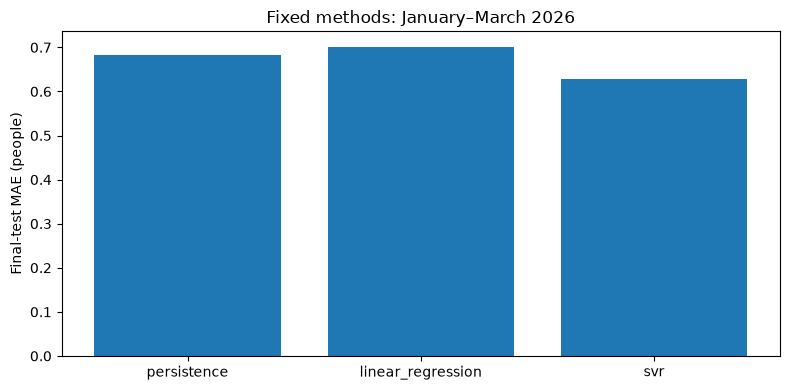

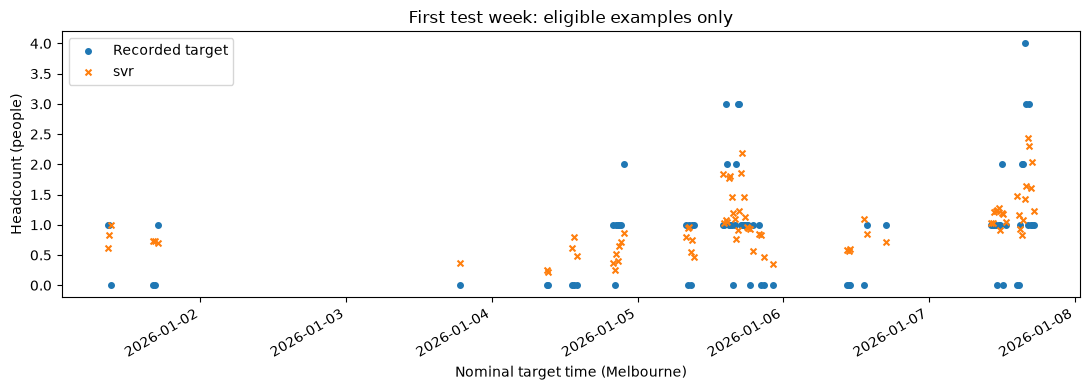

Plotted first-week examples: 77


In [10]:
# Display all three fixed methods rather than only the selected result.
mae_fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(test_scores["model"], test_scores["mae_people"])
ax.set_ylabel("Final-test MAE (people)")
ax.set_title("Fixed methods: January–March 2026")
mae_fig.tight_layout()
plt.show()

selected_predictions = test_predictions[selected_model_name]
target_times = pd.to_datetime(selected_predictions["target_time"], utc=True).dt.tz_convert(settings["local_timezone"])
# Use the first test week so the displayed period is not chosen for flattering results.
week_start = pd.Timestamp(settings["test_start"])
week_end = week_start + pd.Timedelta(days=7)
first_week = (target_times >= week_start) & (target_times < week_end)
week_fig, ax = plt.subplots(figsize=(11, 4))
# Leave missing periods blank rather than implying a continuous observed record.
ax.scatter(target_times[first_week], selected_predictions.loc[first_week, "observed_headcount"], s=16, label="Recorded target")
ax.scatter(target_times[first_week], selected_predictions.loc[first_week, "predicted_headcount"], s=18, marker="x", label=selected_model_name)
ax.set_xlabel("Nominal target time (Melbourne)")
ax.set_ylabel("Headcount (people)")
ax.set_title("First test week: eligible examples only")
ax.legend()
week_fig.autofmt_xdate()
week_fig.tight_layout()
plt.show()
print("Plotted first-week examples:", int(first_week.sum()))

### Save the complete evidence and small report-ready summaries


In [11]:
# Keep small summaries with the documentation while full predictions remain in local outputs.
results_folder = project_root / "docs" / "results" / space_prefix
results_folder.mkdir(parents=True, exist_ok=True)
summary_tables = {
    "comparison_metrics.csv": all_scores,
    "computational_costs.csv": timing,
    "monthly_test_metrics.csv": monthly_test_scores,
    "test_output_checks.csv": quality,
    "data_coverage.csv": coverage,
}
for filename, table in summary_tables.items():
    table.to_csv(output_folder / filename, index=False)
    table.to_csv(results_folder / filename, index=False)
validation_scores.to_csv(output_folder / "validation_selection.csv", index=False)
test_scores.to_csv(output_folder / "test_comparison.csv", index=False)
for name, predictions in test_predictions.items():
    predictions.to_csv(output_folder / f"{name}_test_predictions.csv", index=False)
mae_fig.savefig(output_folder / "test_mae_comparison.png", dpi=160, bbox_inches="tight")
mae_fig.savefig(results_folder / "test_mae_comparison.png", dpi=160, bbox_inches="tight")
week_fig.savefig(output_folder / "test_first_week.png", dpi=160, bbox_inches="tight")

selected_test = test_scores.loc[test_scores["model"] == selected_model_name].iloc[0]
selected_change = float(selected_test["mae_reduction_vs_persistence_percent"])
change_text = (f"{selected_change:.2f}%" if np.isfinite(selected_change) else "undefined (zero baseline MAE)")
# Generate the summary from computed results so copied values cannot drift from the tables.
summary_lines = [
    "# Single-space final evaluation", "",
    f"Space ID: `{settings['space_id']}`. Nominal forecast horizon: 30 minutes.",
    "",
    "## Decision fixed before testing",
    f"Selected method: **{selected_model_name}**, using validation MAE (RMSE breaks exact ties).",
    f"SVR settings previously selected in Notebook 5: `{selected_parameters}`.",
    "Both learned models retain the training-only fit period; validation data was not added to fitting.",
    "All three methods were specified before test exposure. Their test results are reported without retuning.",
    "",
    "## Recorded results", "",
    "| Method | Period | Examples | MAE (people) | RMSE (people) |",
    "|---|---|---:|---:|---:|",
]
for row in all_scores.itertuples(index=False):
    summary_lines.append(f"| {row.model} | {row.split} | {row.examples} | {row.mae_people:.4f} | {row.rmse_people:.4f} |")
summary_lines += [
    "", f"Validation-selected method's test MAE reduction relative to persistence: **{change_text}**.",
    "Positive means lower error; negative means worse error. This is not percentage accuracy.",
    "", "## Scope and limitations",
    "- Results concern one monitored space and the retained complete examples, not all spaces or all hours.",
    "- Targets are sensor-reported readings no more than five minutes before nominal target time; independent physical headcounts are unavailable.",
    "- Complete-case filtering can favour frequently reported periods. Overlapping forecast examples are not independent experiments.",
    "- Fractional and negative predictions are evaluated unchanged; see test_output_checks.csv for physical-output limitations.",
    "- The test set is now exposed. Do not use these results to tune parameters and still call it an untouched final test.",
    "- No statistical-significance claim, HVAC energy saving, thermal comfort improvement or real-time deployment suitability is established.",
    "- Runtime figures are local measurements; per-example batch time is not single-forecast latency. SVR search cost is separate from one selected fit.",
    "- If test behaviour differs from validation, report it. Do not select a different final method solely because it has the lowest test error.",
    "", "## Reproduction",
    "Generated by notebooks/6_model_comparison.ipynb after Notebooks 2–5. Raw and prepared data remain outside Git.",
    f"Versions: Python {platform.python_version()}, NumPy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}.",
    "The protocol and run information record data/source fingerprints and first-exposure metadata.",
    "AI-assisted code and draft explanations require disclosure; this generated text does not claim the student's independent verification.",
]
summary_text = "\n".join(summary_lines) + "\n"
(output_folder / "final_evaluation_summary.md").write_text(summary_text, encoding="utf-8")
(results_folder / "final_evaluation_summary.md").write_text(summary_text, encoding="utf-8")
(results_folder / "evaluation_protocol.json").write_text(protocol_path.read_text(encoding="utf-8"), encoding="utf-8")

# Retain the evaluation history and file fingerprints rather than presenting a rerun as a new test.
run_information = {
    "selected_by_validation": selected_model_name,
    "evaluated_partitions": ["train", "validation", "test"],
    "test_data_used": True,
    "test_used_for_model_selection_or_fitting": False,
    "protocol_sha256": protocol_hash,
    "csv_sha256": {**fingerprints, "test": test_hash},
    "test_exposure_record": exposure_record,
    "source_sha256": source_hashes,
    "versions": protocol["versions"],
    "test_examples": len(test),
    "common_feature_encoding_seconds": feature_encoding_seconds,
    "fit_seconds_this_run": fit_seconds,
    "output_policy": protocol["output_policy"],
    "completed_utc": datetime.now(timezone.utc).isoformat(),
}
for folder in [output_folder, results_folder]:
    (folder / "run_information.json").write_text(json.dumps(run_information, indent=2), encoding="utf-8")
print("Detailed outputs:", output_folder)
print("Small report-ready summaries:", results_folder)
display(Markdown(summary_text))

Detailed outputs: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project\outputs\227f1068\comparison
Small report-ready summaries: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project\docs\results\227f1068


# Single-space final evaluation

Space ID: `227f1068-9e41-469f-bef0-275f27a0bdba`. Nominal forecast horizon: 30 minutes.

## Decision fixed before testing
Selected method: **svr**, using validation MAE (RMSE breaks exact ties).
SVR settings previously selected in Notebook 5: `{'C': 10.0, 'epsilon': 0.1, 'gamma': 0.01}`.
Both learned models retain the training-only fit period; validation data was not added to fitting.
All three methods were specified before test exposure. Their test results are reported without retuning.

## Recorded results

| Method | Period | Examples | MAE (people) | RMSE (people) |
|---|---|---:|---:|---:|
| persistence | train | 14772 | 1.2557 | 2.1709 |
| persistence | validation | 3388 | 0.8628 | 1.4057 |
| linear_regression | train | 14772 | 1.1611 | 1.8564 |
| linear_regression | validation | 3388 | 0.8218 | 1.1647 |
| svr | train | 14772 | 1.1056 | 1.8579 |
| svr | validation | 3388 | 0.7815 | 1.1628 |
| persistence | test | 2260 | 0.6819 | 1.0452 |
| linear_regression | test | 2260 | 0.7013 | 0.9098 |
| svr | test | 2260 | 0.6273 | 0.8311 |

Validation-selected method's test MAE reduction relative to persistence: **8.00%**.
Positive means lower error; negative means worse error. This is not percentage accuracy.

## Scope and limitations
- Results concern one monitored space and the retained complete examples, not all spaces or all hours.
- Targets are sensor-reported readings no more than five minutes before nominal target time; independent physical headcounts are unavailable.
- Complete-case filtering can favour frequently reported periods. Overlapping forecast examples are not independent experiments.
- Fractional and negative predictions are evaluated unchanged; see test_output_checks.csv for physical-output limitations.
- The test set is now exposed. Do not use these results to tune parameters and still call it an untouched final test.
- No statistical-significance claim, HVAC energy saving, thermal comfort improvement or real-time deployment suitability is established.
- Runtime figures are local measurements; per-example batch time is not single-forecast latency. SVR search cost is separate from one selected fit.
- If test behaviour differs from validation, report it. Do not select a different final method solely because it has the lowest test error.

## Reproduction
Generated by notebooks/6_model_comparison.ipynb after Notebooks 2–5. Raw and prepared data remain outside Git.
Versions: Python 3.14.6, NumPy 2.5.4, pandas 3.0.6, scikit-learn 1.9.1.
The protocol and run information record data/source fingerprints and first-exposure metadata.
AI-assisted code and draft explanations require disclosure; this generated text does not claim the student's independent verification.
